# Análisis de línea base de arrecifes con BRUVs y AGRRA en R

**Material de capacitación** · César Augusto Egas Vaca · Biólogo Marino, MSc en Ciencia y Sistemas de Información Geográfica

Este cuaderno recorre un flujo de trabajo reproducible para analizar datos de una línea base arrecifal:
videos remotos con cebo (**BRUVs**) y evaluaciones con el protocolo **AGRRA** (bentos, corales y peces),
hasta un **Índice de Salud Arrecifal (ISA)** y un mapa de sitios.

> ⚠️ **Los datos son simulados** (`R/01_simular_datos.R`). Sitios, coordenadas, conteos y tallas son
> inventados con fines didácticos y no representan ningún arrecife real. Los parámetros talla-peso y
> los umbrales del ISA también son de ejemplo (ver la sección final).

**Pregunta de práctica:** ¿hay señales de presión pesquera al comparar 6 sitios de uso pesquero con
6 sitios de una zona de protección?

Cada sección ejecuta un script de la carpeta `R/`; ábrelos para ver el código comentado paso a paso.

## 0. Preparación
Carga los paquetes y crea las carpetas de salida. En el entorno `arrecifes-r` (ver `environment.yml`) todos los paquetes ya están instalados.

In [1]:
source("R/00_paquetes.R", encoding = "UTF-8")
sessionInfo()$R.version$version.string

Listo. Paquetes instalados: dplyr, tidyr, readr, stringr, ggplot2, glmmTMB, emmeans, vegan, DHARMa



[1] "R version 4.5.3 (2026-03-11)"

## 1. Los datos
Seis tablas: sitios, despliegues y anotaciones de BRUVs (MaxN), puntos bentónicos, colonias de coral y conteos de peces por clase de talla.

In [2]:
library(readr); library(dplyr)
sitios <- read_csv("datos/sitios.csv", show_col_types = FALSE)
sitios


Attaching package: ‘dplyr’




The following objects are masked from ‘package:stats’:

    filter, lag




The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




sitio_id,zona,habitat,profundidad_m,lat,lon
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
S01,Uso pesquero,Arrecife frontal,14.4,15.85778,-83.23505
S02,Uso pesquero,Arrecife de parche,12.7,16.01213,-83.32580
S03,Uso pesquero,Arrecife frontal,7.7,15.83846,-83.23573
S04,Uso pesquero,Arrecife de parche,9.4,15.88920,-83.34397
S05,Uso pesquero,Arrecife frontal,12.7,15.93630,-83.39783
S06,Uso pesquero,Arrecife de parche,6.3,15.80030,-83.15930
S07,Protección,Arrecife frontal,11.6,15.87946,-83.03560
S08,Protección,Arrecife de parche,16.3,15.80432,-83.32985
S09,Protección,Arrecife frontal,9.0,15.88539,-83.10753


In [3]:
head(read_csv("datos/bruvs_maxn.csv", show_col_types = FALSE))
head(read_csv("datos/agrra_peces.csv", show_col_types = FALSE))

despliegue_id,sitio_id,fecha,profundidad_m,tiempo_min,especie,maxn
<chr>,<chr>,<date>,<dbl>,<dbl>,<chr>,<dbl>
S01_B1,S01,2026-05-12,15.7,60,Acanthurus coeruleus,7
S01_B1,S01,2026-05-12,15.7,60,Caranx ruber,5
S01_B1,S01,2026-05-12,15.7,60,Haemulon plumierii,9
S01_B1,S01,2026-05-12,15.7,60,Hypanus americanus,1
S01_B1,S01,2026-05-12,15.7,60,Lutjanus apodus,4
S01_B1,S01,2026-05-12,15.7,60,Lutjanus griseus,2


sitio_id,transecto,especie,familia,clase_talla_cm,conteo
<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>
S01,1,Acanthurus chirurgus,Acanthuridae,11-20,5
S01,1,Acanthurus coeruleus,Acanthuridae,11-20,1
S01,1,Acanthurus coeruleus,Acanthuridae,6-10,2
S01,1,Haemulon flavolineatum,Haemulidae,11-20,1
S01,1,Haemulon flavolineatum,Haemulidae,6-10,1
S01,1,Scarus iseri,Scaridae,11-20,4


## 2. Control de calidad
Los datos traen errores a propósito: un nombre científico mal escrito, otro en minúsculas, una fila duplicada
y una colonia de coral con 130 % de mortalidad. Las correcciones quedan escritas en el script, nunca a mano en el CSV.

In [4]:
source("R/02_control_calidad.R", encoding = "UTF-8")

Rows: 258
Columns: 7
$ despliegue_id <chr> "S01_B1", "S01_B1", "S01_B1", "S01_B1", "S01_B1", "S01_B…
$ sitio_id      <chr> "S01", "S01", "S01", "S01", "S01", "S01", "S01", "S01", …
$ fecha         <date> 2026-05-12, 2026-05-12, 2026-05-12, 2026-05-12, 2026-05…
$ profundidad_m <dbl> 15.7, 15.7, 15.7, 15.7, 15.7, 15.7, 15.7, 16.1, 16.1, 16…
$ tiempo_min    <dbl> 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, …
$ especie       <chr> "Acanthurus coeruleus", "Caranx ruber", "Haemulon plumie…
$ maxn          <dbl> 7, 5, 9, 1, 4, 2, 1, 2, 6, 1, 5, 2, 1, 4, 1, 3, 3, 1, 1,…
# A tibble: 1 × 1
  especie               
  <chr>                 
1 Ginglymostoma cirratun
Filas duplicadas en BRUVs: 1 
# A tibble: 0 × 3
# ℹ 3 variables: despliegue_id <chr>, especie <chr>, n <int>
# A tibble: 1 × 9
  sitio_id transecto especie      diam_max_cm mort_antigua_pct mort_reciente_pct
  <chr>        <dbl> <chr>              <dbl>            <dbl>             <dbl>
1 S01              1 Montastraea…    

Control de calidad terminado. Datos en datos_limpios/



## 3. BRUVs: MaxN, riqueza y frecuencia de ocurrencia
**MaxN** es el número máximo de individuos de una especie visibles a la vez en un cuadro del video: una abundancia
relativa y conservadora. La planilla de anotación solo trae lo que se vio, así que primero se completan los ceros
(36 despliegues × 15 especies = 540 filas).

In [5]:
source("R/03_bruvs_maxn.R", encoding = "UTF-8")

Filas:  540  =  36  despliegues x  15  especies
# A tibble: 30 × 7
   grupo          especie          zona  n_despliegues FO_pct maxn_media maxn_ee
   <chr>          <chr>            <chr>         <int>  <dbl>      <dbl>   <dbl>
 1 Comercial      Epinephelus str… Prot…            18   38.9       0.61    0.22
 2 Comercial      Epinephelus str… Uso …            18    5.6       0.06    0.06
 3 Comercial      Lutjanus apodus  Prot…            18   83.3       2.33    0.58
 4 Comercial      Lutjanus apodus  Uso …            18   50         1.22    0.38
 5 Comercial      Lutjanus griseus Prot…            18   44.4       0.72    0.25
 6 Comercial      Lutjanus griseus Uso …            18   50         0.89    0.25
 7 Comercial      Mycteroperca bo… Prot…            18   16.7       0.39    0.24
 8 Comercial      Mycteroperca bo… Uso …            18   11.1       0.11    0.08
 9 Comercial      Ocyurus chrysur… Prot…            18   94.4       5.22    0.91
10 Comercial      Ocyurus chrysur… Uso …  

Listo: tablas y figuras de BRUVs en resultados/



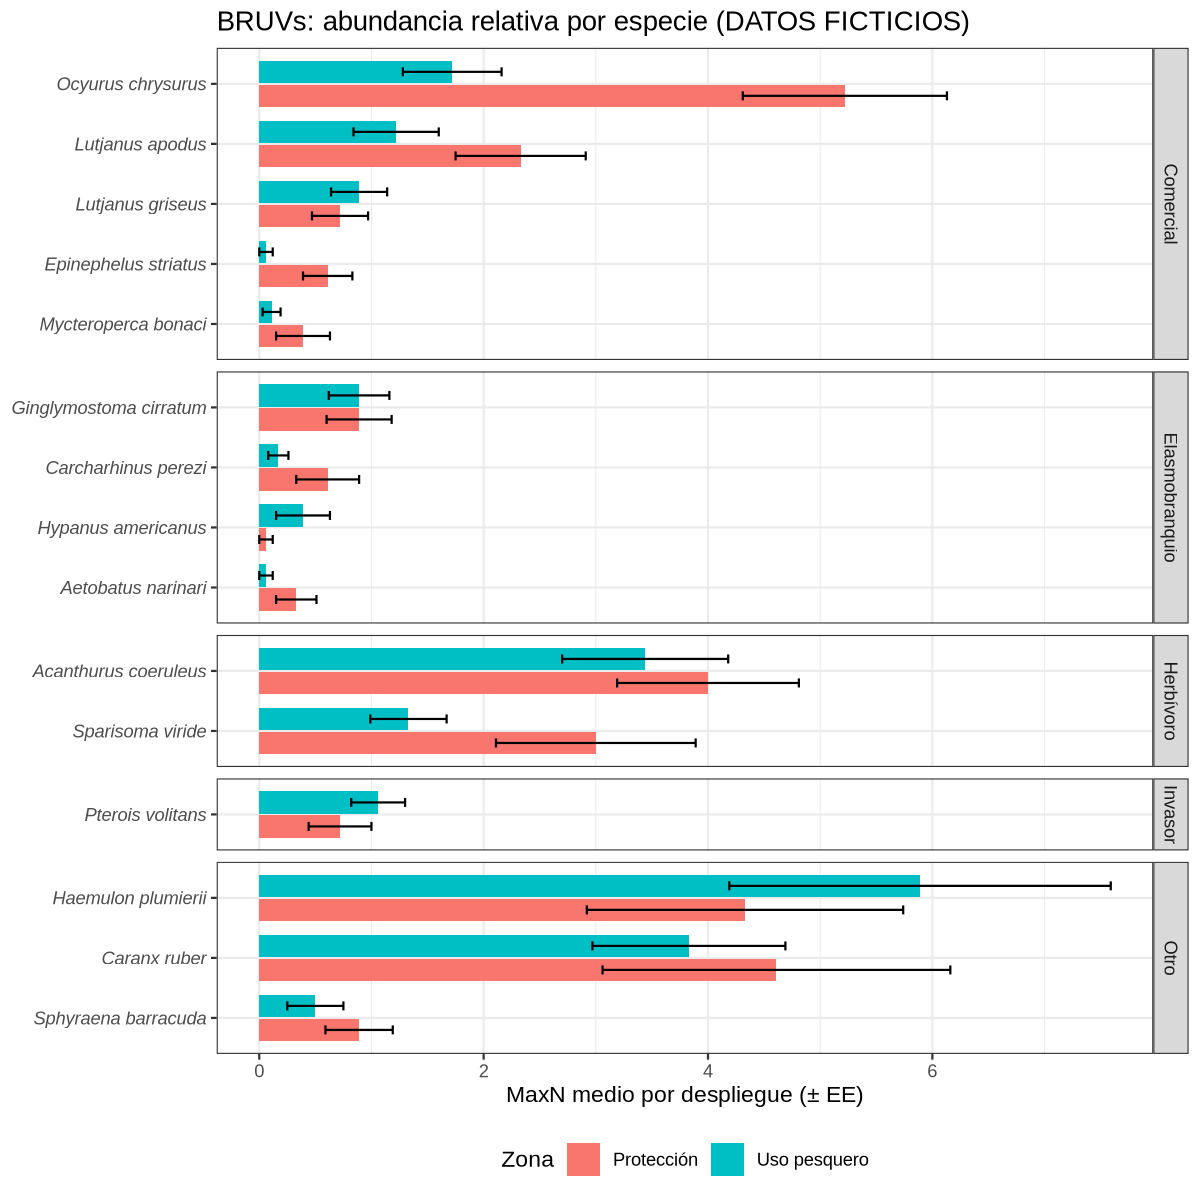

In [6]:
IRdisplay::display_png(file = "resultados/figuras/bruvs_maxn_especies.png")

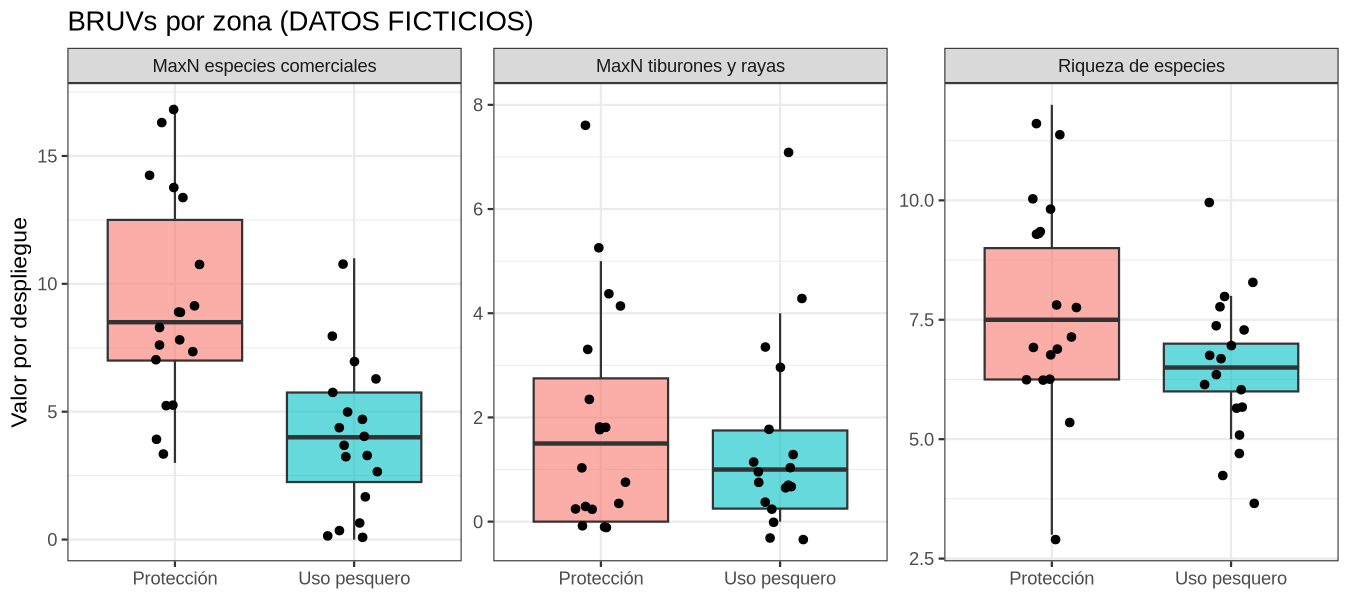

In [7]:
IRdisplay::display_png(file = "resultados/figuras/bruvs_metricas_por_zona.png")

## 4. BRUVs: modelos para conteos
MaxN de tiburones y rayas por despliegue ~ zona + profundidad + (1 | sitio). Se compara Poisson con binomial negativa
(sobredispersión) y se interpreta la razón entre zonas con `emmeans`.

Warning message in check_dep_version(dep_pkg = "TMB"):
“package version mismatch: 
glmmTMB was built with TMB package version 1.9.19
Current TMB package version is 1.9.23
Please re-install glmmTMB from source or restore original ‘TMB’ package (see '?reinstalling' for more information)”


Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'



       df      AIC
m_pois  4 148.5461
m_nb    5 137.1067
Cociente de sobredispersión (Poisson): 2.23 


Warning message in newton(lsp = lsp, X = G$X, y = G$y, Eb = G$Eb, UrS = G$UrS, L = G$L, :
“Fitting terminated with step failure - check results carefully”



	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 0.99695, p-value = 0.904
alternative hypothesis: two.sided




	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 0.96899, p-value = 1
alternative hypothesis: two.sided

 zona         response    SE  df asymp.LCL asymp.UCL
 Protección       1.85 0.501 Inf     1.088      3.15
 Uso pesquero     1.52 0.429 Inf     0.872      2.64

Confidence level used: 0.95 
Intervals are back-transformed from the log scale 
 contrast                  ratio    SE  df null z.ratio p.value
 Uso pesquero / Protección 0.821 0.323 Inf    1  -0.502  0.6159

Tests are performed on the log scale 


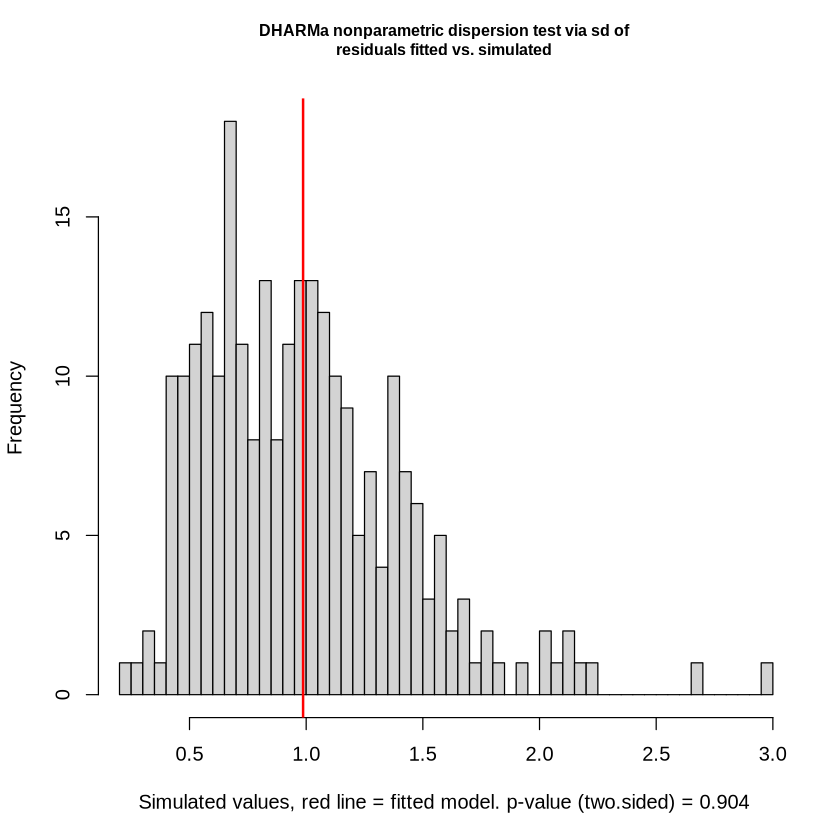

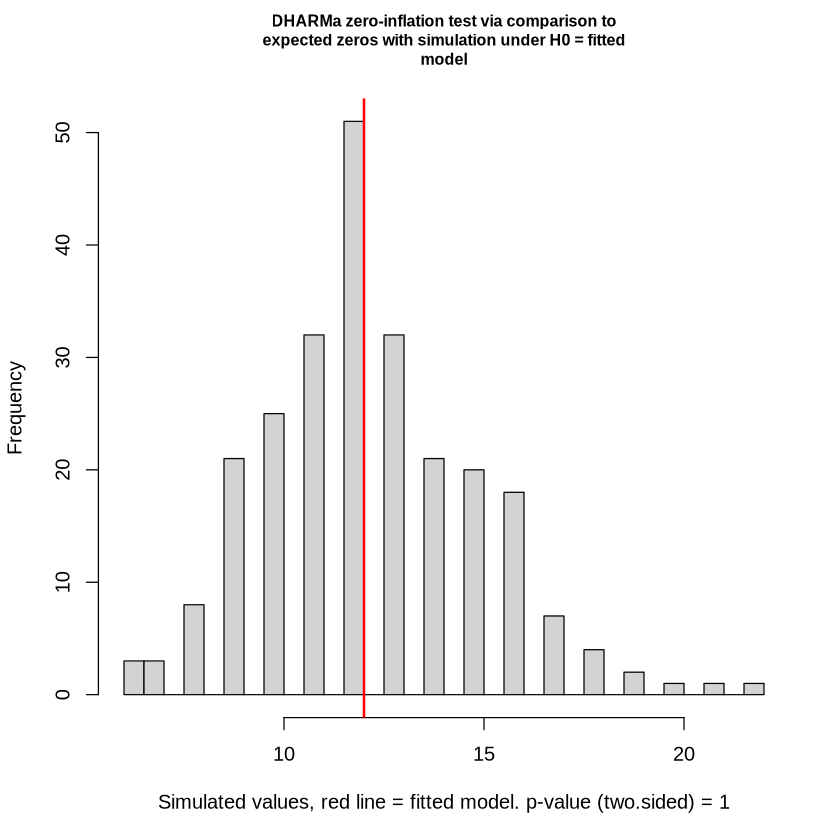

In [8]:
source("R/04_bruvs_modelos.R", encoding = "UTF-8")

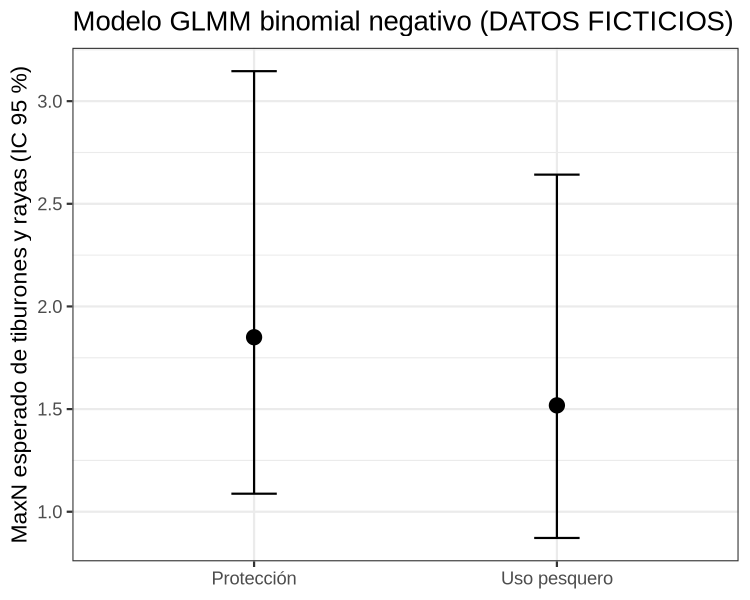

In [9]:
IRdisplay::display_png(file = "resultados/figuras/bruvs_modelo_elasmobranquios.png")

**Lectura:** los datos se simularon con menos elasmobranquios en la zona de pesca, pero con 12 sitios el modelo no
detecta la diferencia (razón ≈ 0,82; p ≈ 0,62). *Sin diferencia significativa* no es *sin efecto*: es falta de poder
estadístico. Repetido con las especies comerciales, la razón es ≈ 0,43 (p < 0,0001).

In [10]:
library(glmmTMB); library(emmeans)
d <- read_csv("resultados/tablas/bruvs_metricas_por_despliegue.csv", show_col_types = FALSE) |>
  mutate(zona = factor(zona), prof_c = profundidad_m - mean(profundidad_m))
m_com <- glmmTMB(maxn_comercial ~ zona + prof_c + (1 | sitio_id), family = nbinom2, data = d)
contrast(emmeans(m_com, ~ zona), method = "revpairwise", type = "response")

 contrast                  ratio     SE  df null z.ratio p.value
 Uso pesquero / Protección  0.43 0.0812 Inf    1  -4.466 <0.0001

Tests are performed on the log scale 

## 5. BRUVs: composición del ensamblaje
nMDS (Bray-Curtis), PERMANOVA a nivel de sitio, SIMPER y curvas de acumulación de especies.

In [11]:
source("R/05_bruvs_multivariado.R", encoding = "UTF-8")

Loading required package: permute



Estrés del nMDS: 0.245 (< 0.2 es aceptable)


Warning message:
“The following aesthetics were dropped during statistical transformation: shape.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”


Permutation test for adonis under reduced model
Marginal effects of terms
Permutation: free
Number of permutations: 999

adonis2(formula = dist_s ~ zona + habitat, data = meta_s, permutations = 999, by = "margin")
         Df SumOfSqs      R2      F Pr(>F)  
zona      1  0.07969 0.17116 2.0813  0.029 *
habitat   1  0.04130 0.08870 1.0786  0.417  
Residual  9  0.34461 0.74014                
Total    11  0.46560 1.00000                
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq   Mean Sq      F N.Perm Pr(>F)
Groups     1 0.003236 0.0032359 0.6682    999  0.486
Residuals 10 0.048427 0.0048427                     
                          average         sd    ratio        ava       avb
Ocyurus chrysurus      0.04178995 0.03170633 1.318032 1.05767415 2.2394257
Haemulon plumierii     0.03472179 0.02128885 1.630984 2.

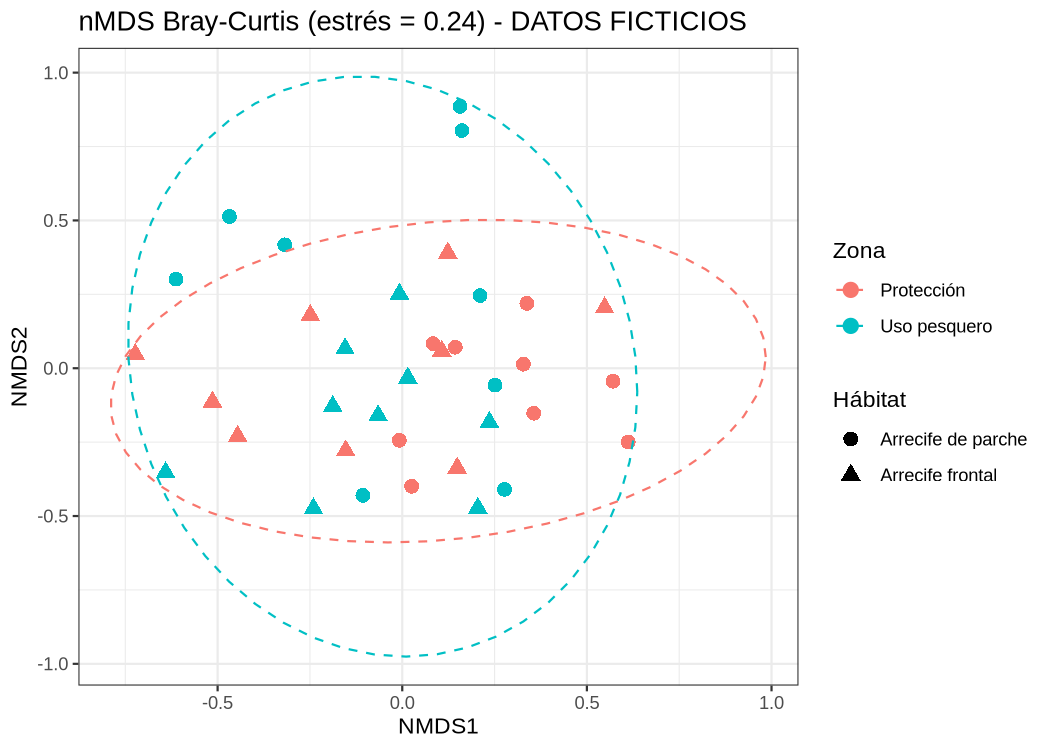

In [12]:
IRdisplay::display_png(file = "resultados/figuras/bruvs_nmds.png")

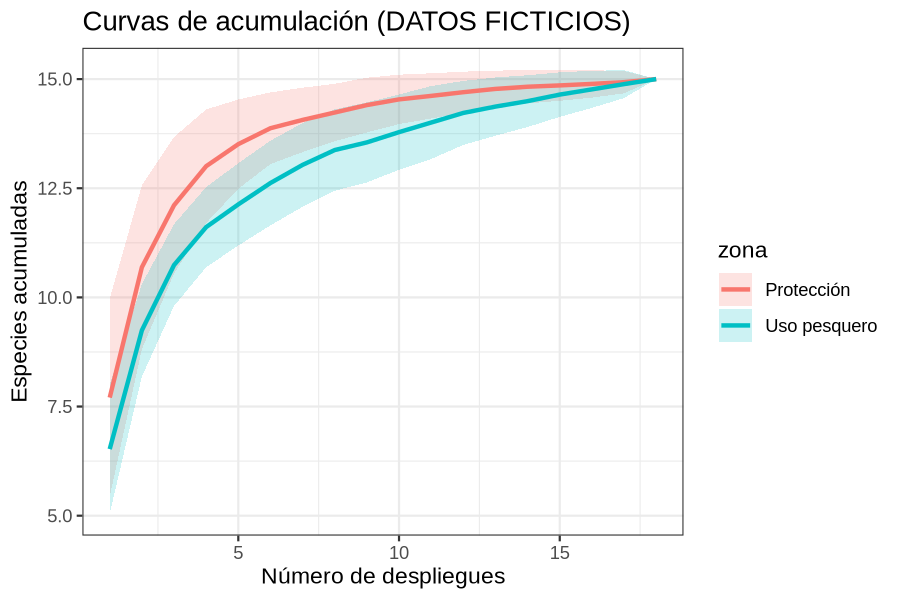

In [13]:
IRdisplay::display_png(file = "resultados/figuras/bruvs_acumulacion_especies.png")

## 6. AGRRA: cobertura bentónica
Cobertura (%) por punto-intercepto: puntos de la categoría / puntos totales × 100, por transecto y luego por sitio.

In [14]:
source("R/06_agrra_bentos.R", encoding = "UTF-8")

# A tibble: 12 × 8
   sitio_id zona         Algas calcáreas costr…¹ `Arena / abiótico` `Coral vivo`
   <chr>    <chr>                          <dbl>              <dbl>        <dbl>
 1 S01      Uso pesquero                     7.6               14.4         13.6
 2 S02      Uso pesquero                     8.4               15.6         11.6
 3 S03      Uso pesquero                     5.8               15.4          9.6
 4 S04      Uso pesquero                     8.4               14.8         12.8
 5 S05      Uso pesquero                     9                 14.2         11.2
 6 S06      Uso pesquero                     8.6               15.4         10.2
 7 S07      Protección                      10.2               17.6         18.2
 8 S08      Protección                       7.8               17.8         18.6
 9 S09      Protección                      10                 15.6         20.4
10 S10      Protección                       9.8               15.8         20  
11 S11   


	Welch Two Sample t-test

data:  cobertura_media by zona
t = 9.6789, df = 9.2327, p-value = 3.892e-06
alternative hypothesis: true difference in means between group Protección and group Uso pesquero is not equal to 0
95 percent confidence interval:
 5.728243 9.205090
sample estimates:
  mean in group Protección mean in group Uso pesquero 
                  18.96667                   11.50000 



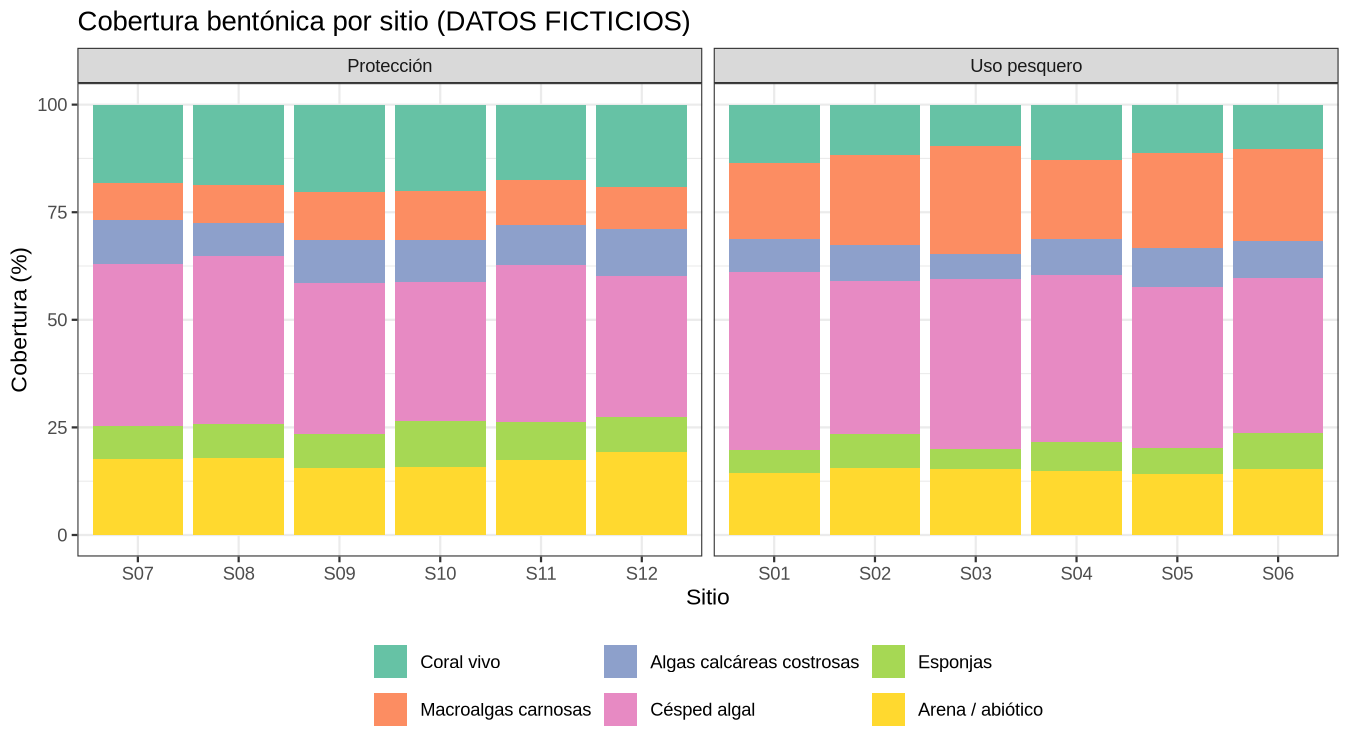

In [15]:
IRdisplay::display_png(file = "resultados/figuras/agrra_cobertura_bentonica.png")

## 7. AGRRA: condición de las colonias de coral

In [16]:
source("R/07_agrra_corales.R", encoding = "UTF-8")

# A tibble: 12 × 9
   sitio_id colonias colonias_por_10m diam_medio_cm mort_antigua_media
   <chr>       <dbl>            <dbl>         <dbl>              <dbl>
 1 S01            42              8.4          31.7               25.6
 2 S02            40              8            31.6               24.3
 3 S03            53             10.6          29.8               24  
 4 S04            43              8.6          32.7               23.5
 5 S05            46              9.2          34.8               21.8
 6 S06            37              7.4          28.9               25.1
 7 S07            42              8.4          36                 20.7
 8 S08            55             11            27.7               25.8
 9 S09            56             11.2          31.2               26.2
10 S10            38              7.6          34                 20.7
11 S11            52             10.4          36.7               25.5
12 S12            41              8.2          30.7       

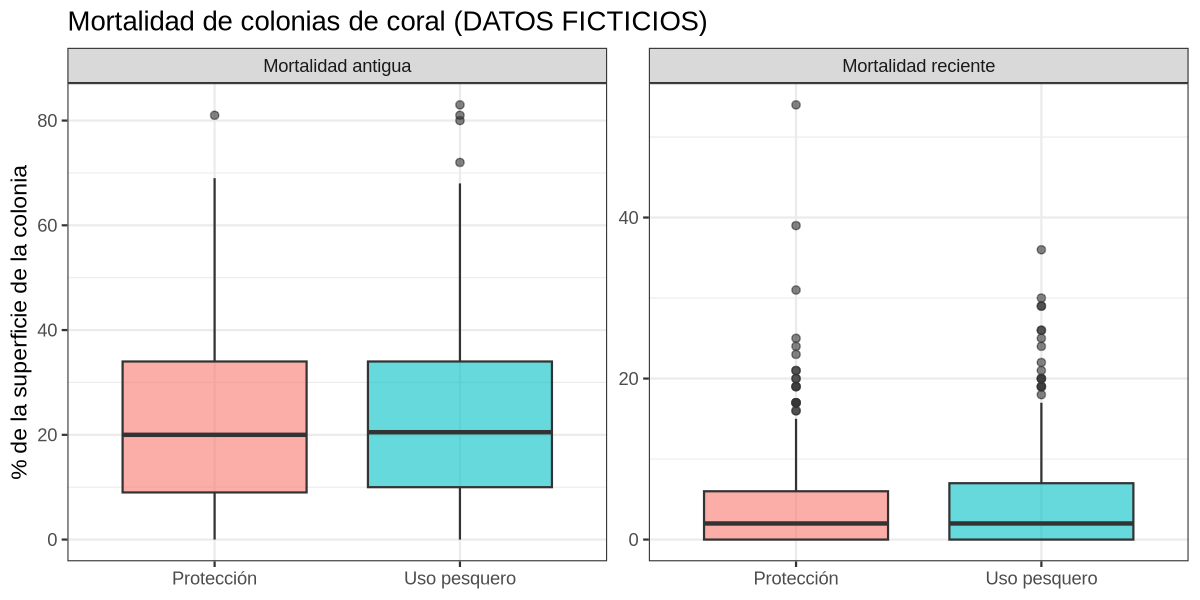

In [17]:
IRdisplay::display_png(file = "resultados/figuras/agrra_corales_mortalidad.png")

## 8. AGRRA: biomasa de peces
Biomasa de cada registro con la relación talla-peso, usando la marca de clase de la talla: $W = a \cdot L^{b} \times n$, expresada en g/100 m².

In [18]:
source("R/08_agrra_peces_biomasa.R", encoding = "UTF-8")

# A tibble: 12 × 5
   sitio_id zona         Comercial Herbívoro  Otro
   <chr>    <chr>            <dbl>     <dbl> <dbl>
 1 S01      Uso pesquero       246      2371   769
 2 S02      Uso pesquero       893      2129   469
 3 S03      Uso pesquero      1606      1499   675
 4 S04      Uso pesquero      1333      1862   628
 5 S05      Uso pesquero      1331      1881   290
 6 S06      Uso pesquero      1160      2291   366
 7 S07      Protección        3287      2947  1566
 8 S08      Protección        2637      2117  1066
 9 S09      Protección        2306      4031   499
10 S10      Protección        2448      3575   929
11 S11      Protección        1499      2716   672
12 S12      Protección        1330      4035   542


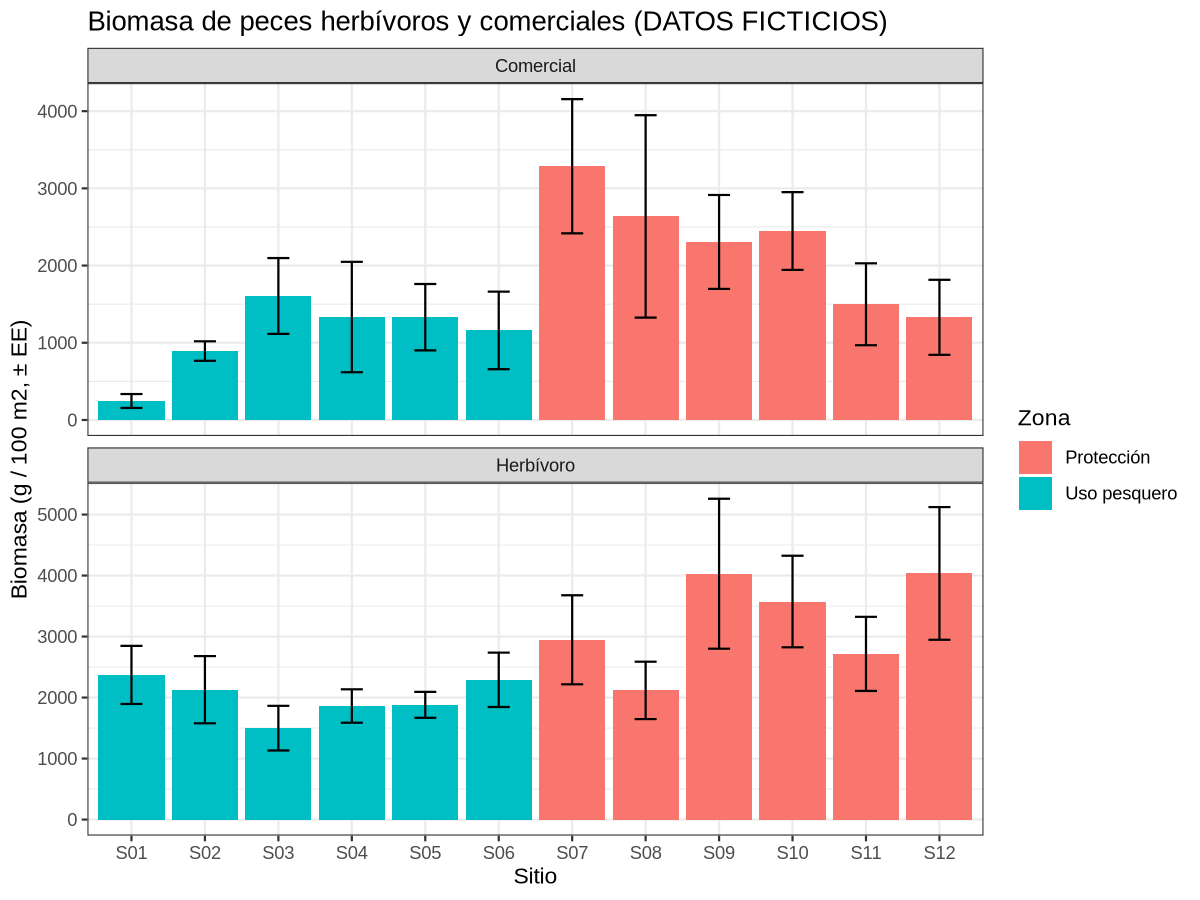

In [19]:
IRdisplay::display_png(file = "resultados/figuras/agrra_peces_biomasa.png")

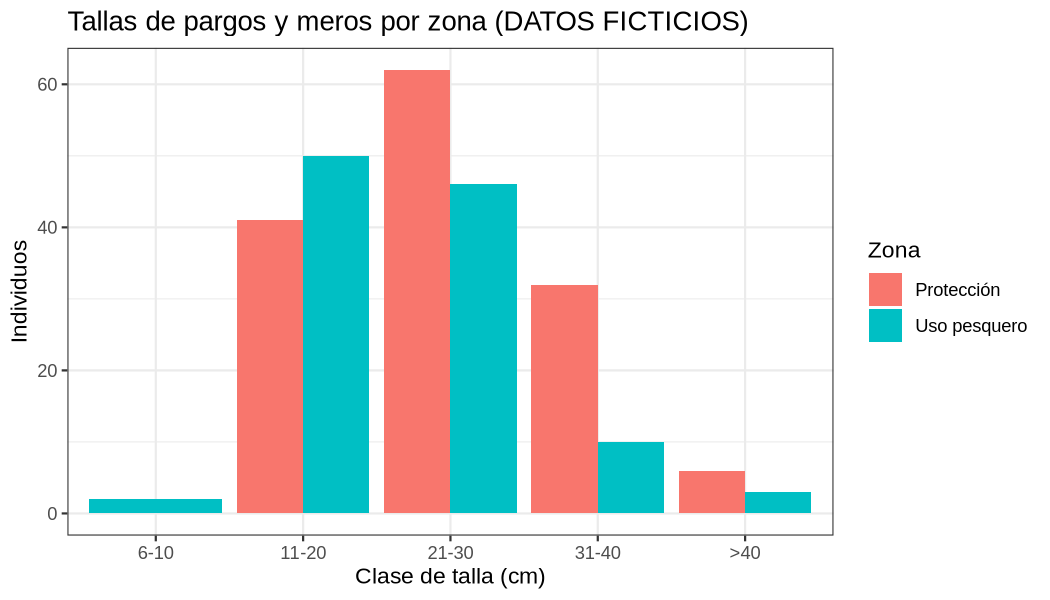

In [20]:
IRdisplay::display_png(file = "resultados/figuras/agrra_peces_tallas_comerciales.png")

## 9. Índice de Salud Arrecifal (ISA)
Cuatro indicadores (coral vivo, macroalgas carnosas, biomasa de herbívoros y de comerciales), cada uno puntuado de 1 a 5; el ISA es el promedio.

In [21]:
source("R/09_indice_salud_arrecifal.R", encoding = "UTF-8")

# A tibble: 12 × 10
   sitio_id coral_vivo_pct macroalgas_pct herbivoros_g100m2 comerciales_g100m2
   <chr>             <dbl>          <dbl>             <dbl>              <dbl>
 1 S09                   4              3                 5                  5
 2 S10                   4              3                 5                  5
 3 S07                   3              3                 4                  5
 4 S12                   3              3                 5                  4
 5 S08                   3              3                 3                  5
 6 S11                   3              3                 3                  4
 7 S04                   3              2                 3                  4
 8 S05                   3              2                 3                  4
 9 S02                   3              2                 3                  3
10 S06                   3              2                 3                  3
11 S01                   3      

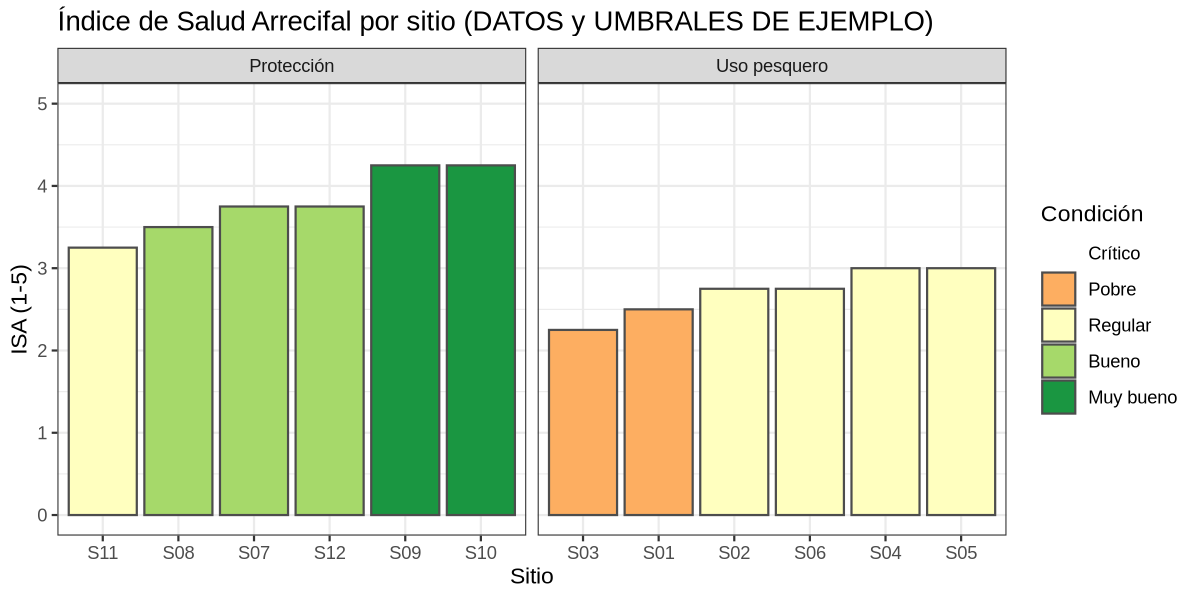

In [22]:
IRdisplay::display_png(file = "resultados/figuras/indice_salud_arrecifal.png")

## 10. Mapa de sitios
Coordenadas ficticias. El script también exporta un CSV listo para abrir en QGIS (EPSG:4326).

In [23]:
source("R/10_mapa_sitios.R", encoding = "UTF-8")

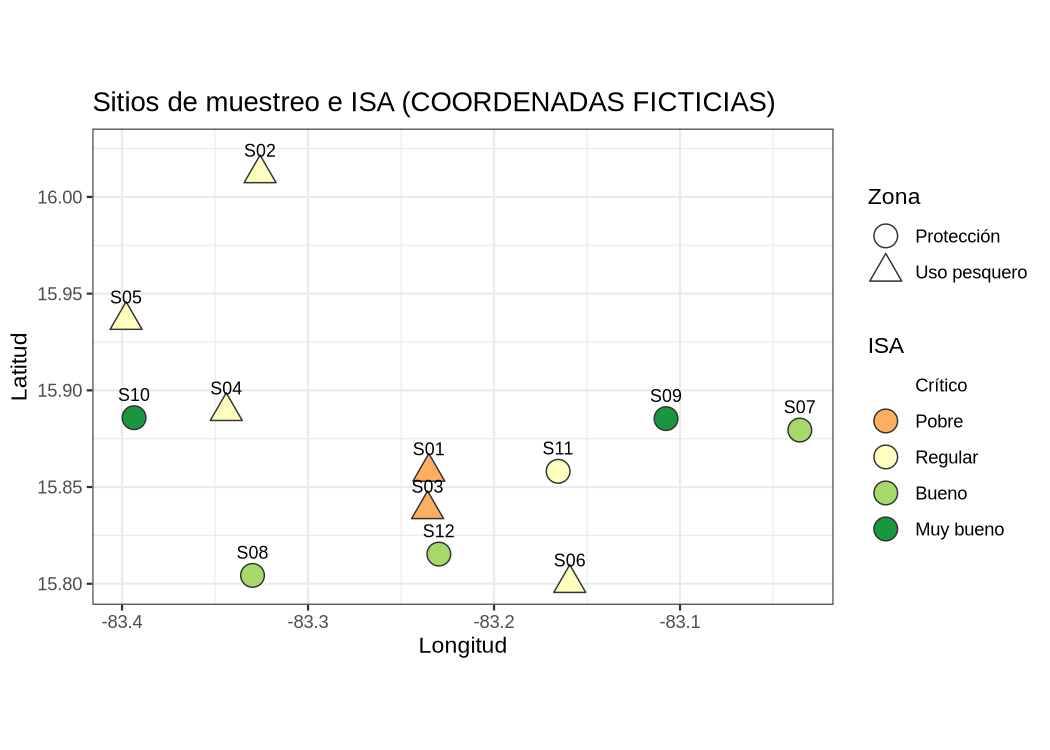

In [24]:
IRdisplay::display_png(file = "resultados/figuras/mapa_sitios_isa.png")

## Advertencias y fuentes
- **Datos:** simulados; no citar como resultados de ningún sitio real.
- **Parámetros talla-peso (a, b):** ilustrativos; usar los de [FishBase](https://www.fishbase.se) para cada especie.
- **Umbrales del ISA:** de ejemplo; usar la tabla oficial del Report Card vigente de la
  [Iniciativa Arrecifes Saludables](https://www.healthyreefs.org).
- **Diseño de muestreo:** confirmar número y largo de transectos, área de las bandas y tiempo de los BRUVs con el protocolo de campo real.

Langlois, T. et al. (2020). A field and video annotation guide for baited remote underwater stereo-video surveys of
demersal fish assemblages. *Methods in Ecology and Evolution*, 11(11), 1401–1409.
[doi:10.1111/2041-210X.13470](https://doi.org/10.1111/2041-210X.13470)